# §5.5 — Sistema de produção offshore (Figuras 31–37, Tabelas 19–22)

Poço vertical de 1500 m, linha horizontal de 6000 m e riser vertical de 300 m (um tubo com perfil
axial), fluido de 9 componentes com C7+ (Tabela 19), 170 bar, 80 °C e 10 kg/s na entrada. Dois
modelos (não escorregamento por marcha; mecanicista por diferenças finitas), corridas
`runs/dissertation/offshore_5_5_{noslip,slip}.npz`; curvas da dissertação («Modelo», «Modelo
no-slip») e do HYSYS (TULSA, Beggs & Brill) digitalizadas das Figuras 32–37. Não simula.

In [1]:
import sys
from pathlib import Path

ROOT = Path(__file__).resolve().parents[2] if "__file__" in globals() else Path.cwd()
sys.path.insert(0, str(ROOT))

import numpy as np

from dissertation.notebook_utils import (
    components_db,
    figure,
    fluids_db,
    load_runs,
    make_fluid,
    MATRIX_HEADERS,
    matrix_rows,
    MODEL_LABEL,
    parity_line,
    plt,
    save,
    SOLVER_LABEL,
    table,
    tables,
)

figs = {n: figure(n) for n in (32, 33, 34, 35, 36, 37)}
runs = load_runs("dissertation/offshore_5_5_*.npz")
runs = {k.replace("offshore_5_5_", ""): v for k, v in runs.items()}
pair = {"noslip": "Modelo no-slip", "slip": "Modelo"}
ALIAS = {"Modelo": ("Modelo", "Modelo mecanístico"), "Modelo no-slip": ("Modelo no-slip",)}  # nomes por figura


def series_of(n, name):
    for alias in ALIAS.get(name, (name,)):
        if alias in figs[n]["series"]:
            return figs[n]["series"][alias]
    return None


print("corridas:", list(runs))
for n in (32, 33, 34, 35, 36, 37):
    print(f"Figura {n}: séries {list(figs[n]['series'])}")

corridas: ['noslip', 'slip']
Figura 32: séries ['Modelo', 'BB', 'TULSA', 'Modelo no-slip']
Figura 33: séries ['Modelo', 'BB', 'TULSA', 'Modelo no-slip']
Figura 34: séries ['Modelo', 'BB', 'TULSA', 'Modelo no-slip']
Figura 35: séries ['Modelo mecanístico', 'Equilíbrio']
Figura 36: séries ['Líquido', 'Vapor']
Figura 37: séries ['Modelo mecanístico', 'Modelo no-slip', 'Tulsa', 'BB']


## Tabelas 19–22 (entradas) e Figura 31 (esquema)

In [2]:
t = tables()
cs, z = make_fluid("table19_offshore")
table([(nm, f"{zi:.3f}") for nm, zi in zip(cs.names, z)], ["componente", "fração molar"])
rows = [
    (
        k,
        f"{v['D']:.4f}",
        f"{v['roughness']*1e3:.1f}",
        f"{v['L']:.0f}",
        f"{v['elevation']:.0f}",
        f"{v['U']:.0f}",
        f"{v['T_amb_C']:.0f}",
    )
    for k, v in t["table21_offshore_pipes"].items()
]
table(rows, ["trecho", "D (m)", "rugosidade (mm)", "L (m)", "elevação (m)", "U (W/m²K)", "T_amb (°C)"])
print("Tabela 22: P_in 170 bar, T_in 80 °C, m 10 kg/s")


def at(n, name, x):
    s = series_of(n, name)
    if s is None:
        return np.nan
    xs, ys = s
    return float(np.interp(x, xs, ys)) if xs.min() <= x <= xs.max() else np.nan

| componente | fração molar |
|---|---|
| CO2 | 0.007 |
| N2 | 0.011 |
| C1 | 0.696 |
| C2 | 0.103 |
| C3 | 0.049 |
| nC4 | 0.032 |
| nC5 | 0.022 |
| nC6 | 0.007 |
| C7plus | 0.073 |
| trecho | D (m) | rugosidade (mm) | L (m) | elevação (m) | U (W/m²K) | T_amb (°C) |
|---|---|---|---|---|---|---|
| well | 0.1270 | 0.2 | 1500 | 1500 | 7 | 40 |
| flowline | 0.1524 | 0.6 | 6000 | 0 | 5 | 12 |
| riser | 0.1524 | 0.6 | 300 | 300 | 5 | 12 |
Tabela 22: P_in 170 bar, T_in 80 °C, m 10 kg/s


## Pontos de quebra: pressão, temperatura, holdup e padrão

In [3]:
rows = []
for k, r in runs.items():
    nm = pair[k]
    for xq in (1500.0, 7500.0, 7799.0):
        i = int(np.argmin(np.abs(r.x - xq)))
        rows.append(
            (
                k,
                f"{xq:.0f}",
                f"{r.P[i]/1e5:.2f}",
                f"{at(32, nm, xq):.2f}",
                f"{r.T[i]-273.15:.1f}",
                f"{at(33, nm, xq):.1f}",
                f"{r['H_L'][i]:.3f}",
                f"{at(34, nm, xq):.3f}",
                f"{r['pattern_code'][i]:.0f}",
                f"{at(37, nm, xq):.0f}",
            )
        )
table(
    rows,
    [
        "modelo",
        "x (m)",
        "P cmfsim",
        "P tese",
        "T cmfsim",
        "T tese",
        "H_L cmfsim",
        "H_L tese",
        "padrão cmfsim",
        "padrão tese",
    ],
)

| modelo | x (m) | P cmfsim | P tese | T cmfsim | T tese | H_L cmfsim | H_L tese | padrão cmfsim | padrão tese |
|---|---|---|---|---|---|---|---|---|---|
| noslip | 1500 | 119.98 | 119.97 | 65.9 | 67.3 | 0.324 | 0.276 | 2 | 1 |
| noslip | 7500 | 114.39 | 116.11 | 42.0 | 41.8 | 0.360 | 0.308 | 2 | 2 |
| noslip | 7799 | 105.16 | nan | 39.1 | nan | 0.339 | nan | 2 | nan |
| slip | 1500 | 115.62 | 120.30 | 65.5 | 63.8 | 0.382 | 0.338 | 2 | 2 |
| slip | 7500 | 102.27 | 115.26 | 41.2 | 40.0 | 0.334 | 0.397 | 2 | 2 |
| slip | 7799 | 91.48 | nan | 38.0 | nan | 0.447 | nan | 2 | nan |


## Figuras 32–34 e 37 — perfis

figura: notebooks/figs/nb_5_5_fig32_37.png


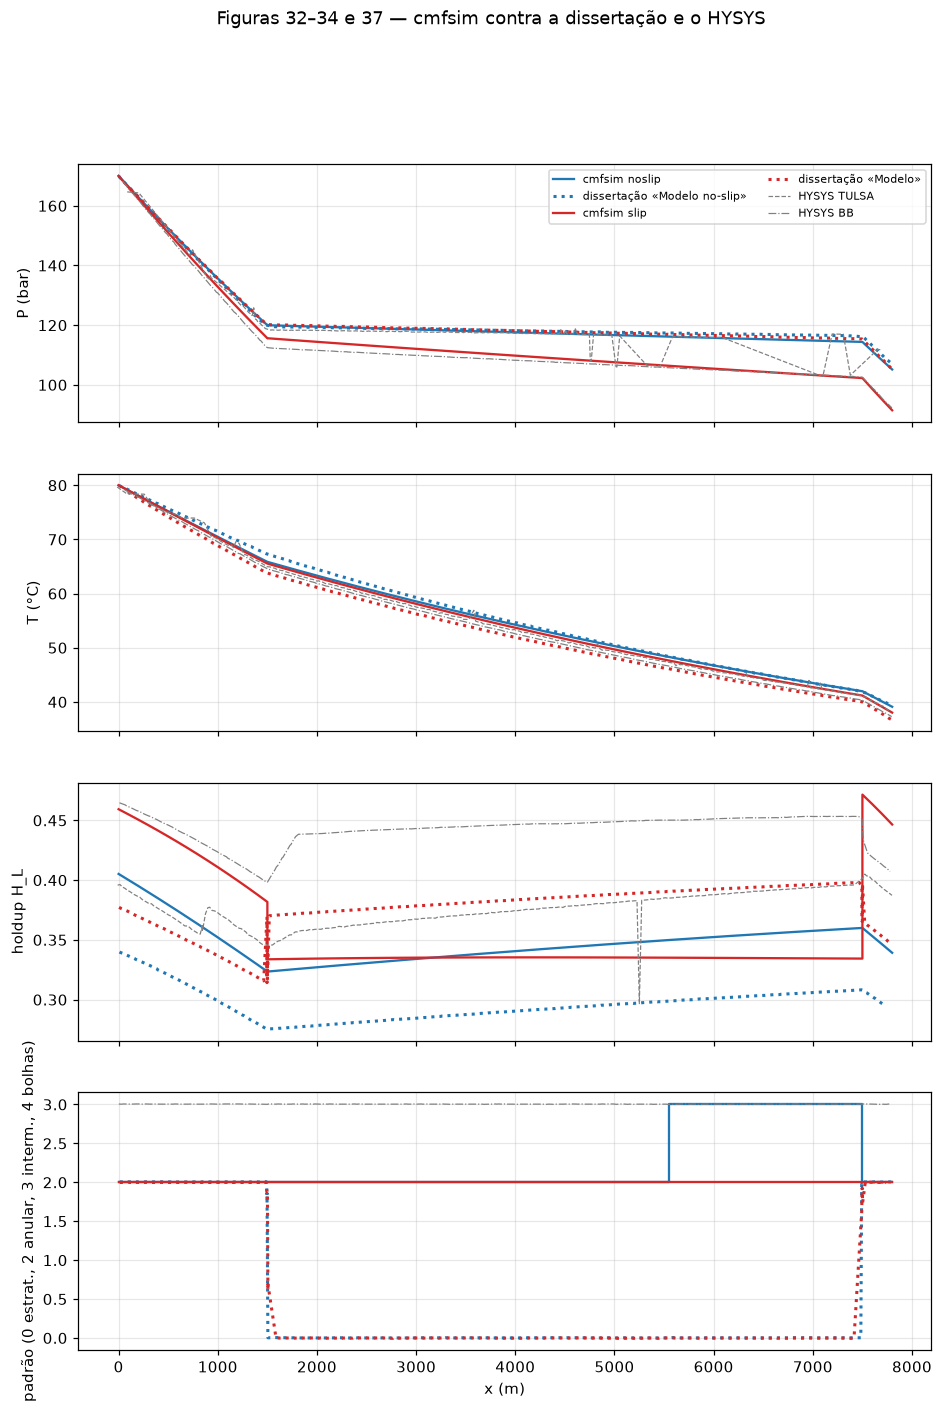

In [4]:
fig, axes = plt.subplots(4, 1, figsize=(10, 14), sharex=True)
for k, r in runs.items():
    c = "C0" if k == "noslip" else "C3"
    nm = pair[k]
    axes[0].plot(r.x, r.P / 1e5, color=c, label=f"cmfsim {k}")
    axes[1].plot(r.x, r.T - 273.15, color=c)
    axes[2].plot(r.x, r["H_L"], color=c)
    axes[3].plot(r.x, r["pattern_code"], color=c, drawstyle="steps-post")
    for ax, n in zip(axes, (32, 33, 34, 37)):
        s = series_of(n, nm)
        if s is not None:
            ax.plot(*s, ":", color=c, lw=2, label=f"dissertação «{nm}»" if ax is axes[0] else None)
for nm, ls in (("TULSA", "--"), ("BB", "-."), ("Beggs & Brill", "-.")):
    for ax, n in zip(axes, (32, 33, 34, 37)):
        if nm in figs[n]["series"]:
            ax.plot(*figs[n]["series"][nm], ls, lw=0.8, color="gray", label=f"HYSYS {nm}" if ax is axes[0] else None)
axes[0].set_ylabel("P (bar)")
axes[1].set_ylabel("T (°C)")
axes[2].set_ylabel("holdup H_L")
axes[3].set_ylabel("padrão (0 estrat., 2 anular, 3 interm., 4 bolhas)")
axes[3].set_xlabel("x (m)")
axes[0].legend(fontsize=7, ncol=2)
for ax in axes:
    ax.grid(alpha=0.3)
fig.suptitle("Figuras 32–34 e 37 — cmfsim contra a dissertação e o HYSYS")
save(fig, "nb_5_5_fig32_37")

## Figura 35 — fração de líquido: flash (equilíbrio) contra mecanicista

figura: notebooks/figs/nb_5_5_fig35.png


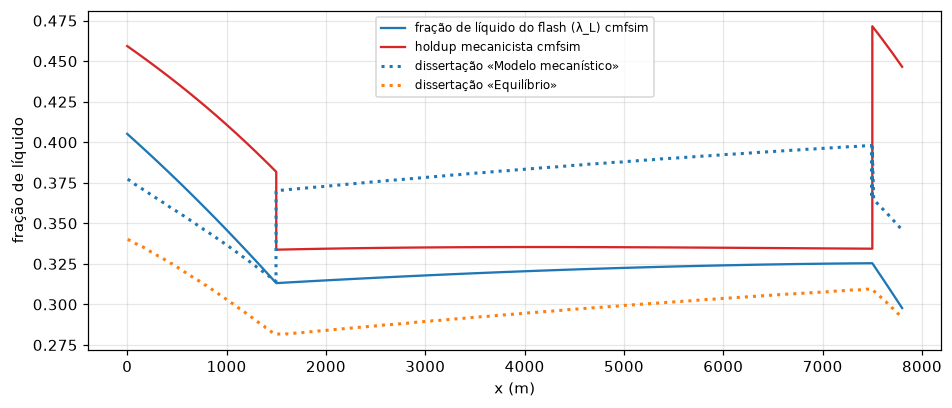

In [5]:
if "slip" in runs:
    r = runs["slip"]
    fig, ax = plt.subplots(figsize=(10, 4))
    ax.plot(r.x, r["H_L_noslip"], "C0", label="fração de líquido do flash (λ_L) cmfsim")
    ax.plot(r.x, r["H_L"], "C3", label="holdup mecanicista cmfsim")
    for nm, (x, y) in figs[35]["series"].items():
        ax.plot(x, y, ":", lw=2, label=f"dissertação «{nm}»")
    ax.set_xlabel("x (m)")
    ax.set_ylabel("fração de líquido")
    ax.legend(fontsize=8)
    ax.grid(alpha=0.3)
    save(fig, "nb_5_5_fig35")

## Figura 36 — CO₂ nas fases líquido e vapor ao longo do escoamento

figura: notebooks/figs/nb_5_5_fig36.png


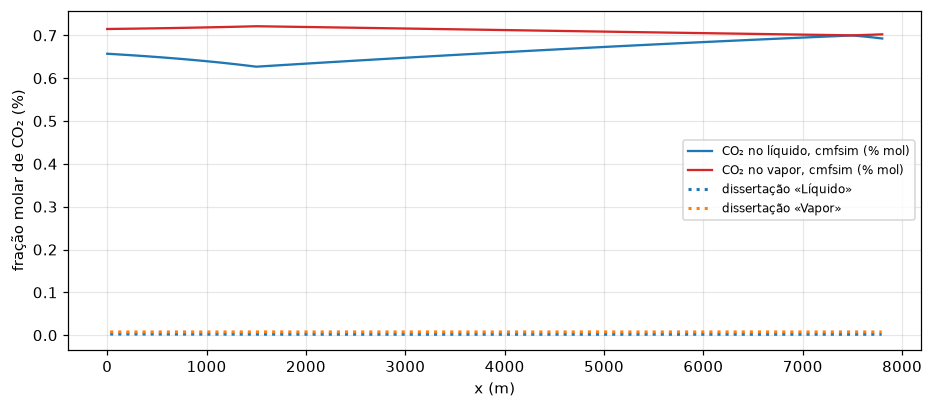

Figura 36: eixos Fração molar no líquido / Fração molar no vapor


In [6]:
r = runs.get("slip", runs.get("noslip"))
if r is not None:
    i_co2 = list(cs.names).index("CO2")
    fig, ax = plt.subplots(figsize=(10, 4))
    ax.plot(r.x, 100 * r["x_comp"][:, i_co2], "C0", label="CO₂ no líquido, cmfsim (% mol)")
    ax.plot(r.x, 100 * r["y_comp"][:, i_co2], "C3", label="CO₂ no vapor, cmfsim (% mol)")
    for nm, (x, y) in figs[36]["series"].items():
        ax.plot(x, y, ":", lw=2, label=f"dissertação «{nm}»")
    ax.set_xlabel("x (m)")
    ax.set_ylabel("fração molar de CO₂ (%)")
    ax.legend(fontsize=8)
    ax.grid(alpha=0.3)
    save(fig, "nb_5_5_fig36")
    print(
        f"Figura 36: eixos {figs[36]['axes']['y'].get('label')} / {figs[36]['axes'].get('y2', {}).get('label') if isinstance(figs[36]['axes'].get('y2'), dict) else ''}"
    )

## Figura 34 — o desfasamento do holdup é termodinâmico (C7+ da Tabela 20)

A curva «Modelo no-slip» da dissertação é 0,85× a nossa λ_L nos três troços, e a mecanicista
0,82× no poço. λ_L = Q_L/(Q_L + Q_G) só depende do flash (w_G, ρ_L, ρ_V), e o líquido é 66 % C7+
em massa (MW 560, ω 1,32, ρ de referência 950 kg/m³ na Tabela 20, que não usamos). Abaixo, a razão
por troço e o que seria preciso mudar no C7+ (ou na massa específica do líquido) para obter a
curva da dissertação (issue 004, «Achados nas Figuras 34 e 40»).

In [7]:
if "noslip" in runs:
    import copy

    from cmfsim.thermo import ComponentSet

    r = runs["noslip"]
    xs34, ys34 = series_of(34, "Modelo no-slip")
    rows = []
    for seg, (a, b) in (("poço", (100, 1450)), ("linha", (1600, 7400)), ("riser", (7550, 7780))):
        xx = np.linspace(a, b, 12)
        yd = np.interp(xx, xs34, ys34)
        ours = np.interp(xx, r.x, r["H_L"])
        rows.append((seg, f"{yd.mean():.3f}", f"{ours.mean():.3f}", f"{np.mean(yd / ours):.3f}"))
    table(rows, ["troço", "λ_L dissertação", "λ_L cmfsim", "razão"])
    comp = components_db()
    fl = fluids_db()["table19_offshore"]
    names = list(fl)
    zz = np.array([fl[k] for k in names])
    zz = zz / zz.sum()
    idx = [int(np.argmin(np.abs(r.x - x0))) for x0 in (200.0, 4000.0, 7000.0)]
    T3, P3 = r.T[idx], r.P[idx]

    def lam_of(recs, kij=None):
        cs_ = ComponentSet.from_records([dict(id=k, **recs[k]) for k in names], kij=kij)
        st_ = phase_state(T3, P3, zz, cs_)
        return (1 - st_.w_G) / st_.rho_L / ((1 - st_.w_G) / st_.rho_L + st_.w_G / st_.rho_V), st_

    from cmfsim.thermo import phase_state

    base, st0 = lam_of(comp)
    yd3 = np.interp(r.x[idx], xs34, ys34)
    rows = [
        ("dissertação (Figura 34)", *[f"{v:.3f}" for v in yd3]),
        ("cmfsim (Tabela 20, k_ij = 0)", *[f"{v:.3f}" for v in base]),
    ]
    for key, fac in (("Pc", 1.25), ("omega", 0.8), ("Tc", 0.95)):
        rec = copy.deepcopy(comp)
        rec["C7plus"][key] = comp["C7plus"][key] * fac
        rows.append((f"C7+ {key} ×{fac}", *[f"{v:.3f}" for v in lam_of(rec)[0]]))
    n = len(names)
    i7 = names.index("C7plus")
    kij = np.zeros((n, n))
    kij[i7, :] = 0.1
    kij[:, i7] = 0.1
    kij[i7, i7] = 0.0
    rows.append(("k_ij(C7+, outros) = 0,1", *[f"{v:.3f}" for v in lam_of(comp, kij)[0]]))
    rho_need = (1 - st0.w_G) / (yd3 / (1 - yd3) * st0.w_G / st0.rho_V)
    rows.append(("ρ_L necessária com o nosso flash [kg/m³]", *[f"{v:.0f}" for v in rho_need]))
    rows.append(("ρ_L da PR [kg/m³]", *[f"{v:.0f}" for v in st0.rho_L]))
    table(rows, ["hipótese", f"x = {r.x[idx[0]]:.0f} m", f"{r.x[idx[1]]:.0f} m", f"{r.x[idx[2]]:.0f} m"])

| troço | λ_L dissertação | λ_L cmfsim | razão |
|---|---|---|---|
| poço | 0.308 | 0.364 | 0.847 |
| linha | 0.293 | 0.343 | 0.853 |
| riser | 0.299 | 0.349 | 0.858 |
| hipótese | x = 200 m | 4000 m | 7000 m |
|---|---|---|---|
| dissertação (Figura 34) | 0.333 | 0.290 | 0.306 |
| cmfsim (Tabela 20, k_ij = 0) | 0.395 | 0.341 | 0.358 |
| C7+ Pc ×1.25 | 0.329 | 0.284 | 0.298 |
| C7+ omega ×0.8 | 0.414 | 0.354 | 0.372 |
| C7+ Tc ×0.95 | 0.392 | 0.336 | 0.353 |
| k_ij(C7+, outros) = 0,1 | 0.347 | 0.301 | 0.313 |
| ρ_L necessária com o nosso flash [kg/m³] | 859 | 838 | 838 |
| ρ_L da PR [kg/m³] | 656 | 664 | 664 |


## Matriz de métodos: dois modelos × três solvers × dois backends (issue 011)

Os dois modelos escrevem-se como d(Φ)/dx = S com fechamentos locais, e os três solvers são três
discretizações da mesma coisa: a marcha (RK45 adaptativo em x), as diferenças finitas nos fluxos
(M Φ = S, Tabela 4 da dissertação) e os volumes finitos (Φ_{i+1} − Φ_i = ∫ S, conservativos por
construção). Corridas do lote `batches/solver_matrix.json` (`runs/solver_matrix/`), 78 nós como
a dissertação; JAX em destaque, numpy só na linha de paridade. Os balanços globais são
(Φ_out − Φ_in) − ∫ S na malha do próprio solver: nos volumes finitos fecham a precisão de máquina.

In [8]:
mruns = load_runs("solver_matrix/offshore_*.npz")
print("corridas:", sorted(mruns))
table(matrix_rows(mruns, "offshore_", x_end=7800.0), MATRIX_HEADERS)
print(parity_line(mruns, "offshore_noslip_fv", "offshore_noslip_fv_numpy"))
print(parity_line(mruns, "offshore_slip_march", "offshore_slip_march_numpy"))
print(parity_line(mruns, "offshore_noslip_march", "offshore_noslip_fv"))
print(parity_line(mruns, "offshore_slip_fd", "offshore_slip_fv"))

corridas: ['offshore_noslip_fd', 'offshore_noslip_fv', 'offshore_noslip_fv_numpy', 'offshore_noslip_march', 'offshore_slip_fd', 'offshore_slip_fv', 'offshore_slip_march', 'offshore_slip_march_numpy']
| modelo | solver | backend | P_out [bar] | T_out [°C] | iterações | balanço momento [Pa] | balanço energia [J/kg] | tempo [s] |
|---|---|---|---|---|---|---|---|---|
| não escorregamento | diferenças finitas | jax | 105.1538 | 39.105 | Newton 1, |F| 9e-12 | -2.5e+02 | +1.8e+00 | 77.82 |
| não escorregamento | volumes finitos | jax | 105.1559 | 39.104 | Newton 1, |F| 3e-14 | +1.3e-06 | +6.4e-07 | 35.36 |
| não escorregamento | volumes finitos | numpy | 105.1559 | 39.104 | Newton 1, |F| 4e-14 | -8.6e-06 | +6.1e-07 | 15.31 |
| não escorregamento | marcha (RK45) | jax | 105.1552 | 39.104 | 158+0 passos | -2.2e+01 | +1.5e-01 | 52.61 |
| mecanicista | diferenças finitas | jax | 91.4768 | 38.028 | Newton 3, |F| 1e-14 | -3.8e+02 | +1.6e+00 | 68.73 |
| mecanicista | volumes finitos | jax | 91.4814

figura: notebooks/figs/nb_5_5_solver_matrix.png


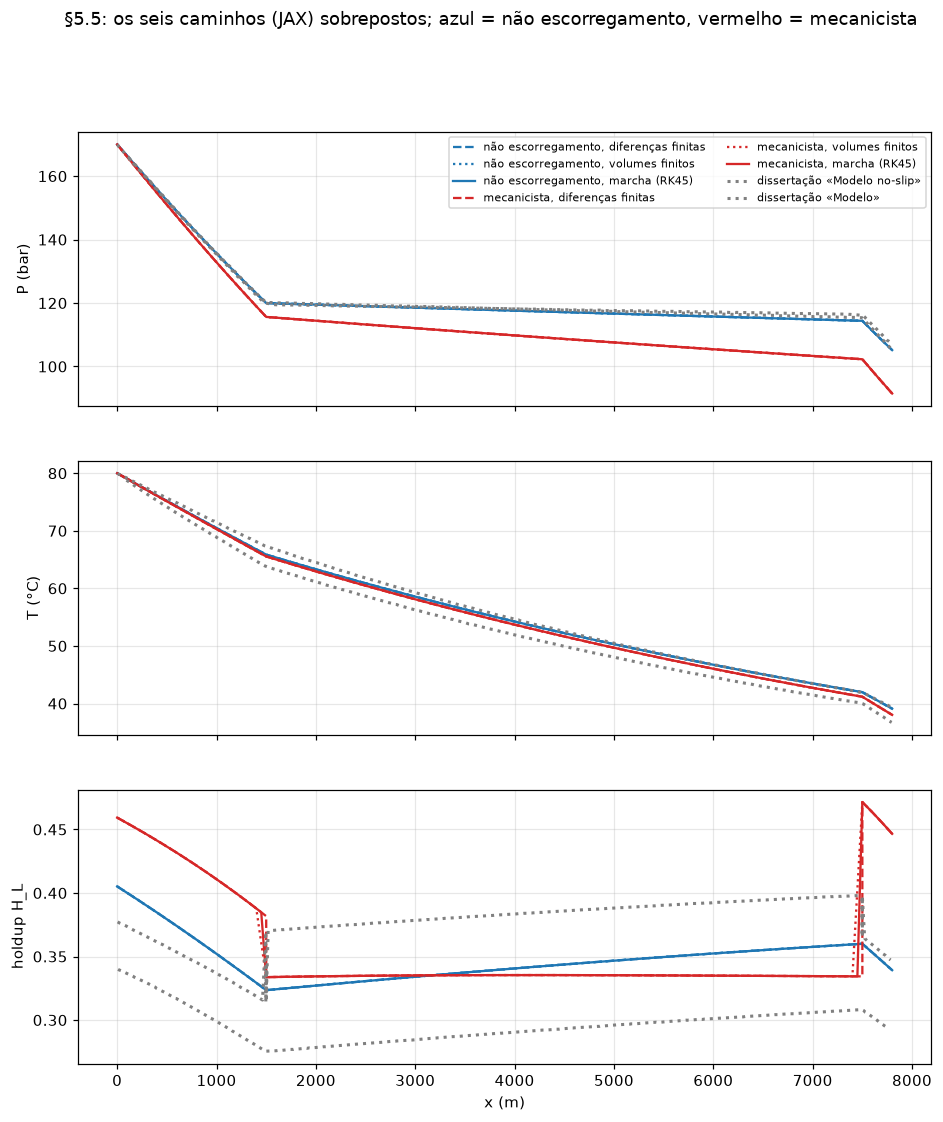

In [9]:
if mruns:
    fig, axes = plt.subplots(3, 1, figsize=(10, 11), sharex=True)
    styles = {"march": "-", "fd": "--", "fv": ":"}
    for name in sorted(mruns):
        if name.endswith("_numpy"):
            continue
        r = mruns[name]
        c = "C0" if r.info["model"] == "noslip" else "C3"
        lab = f"{MODEL_LABEL[r.info['model']]}, {SOLVER_LABEL[r.info['solver']]}"
        axes[0].plot(r.x, r.P / 1e5, styles[r.info["solver"]], color=c, label=lab)
        axes[1].plot(r.x, r.T - 273.15, styles[r.info["solver"]], color=c)
        axes[2].plot(r.x, r["H_L"], styles[r.info["solver"]], color=c)
    for n, key, ax in ((32, "P", axes[0]), (33, "T", axes[1]), (34, "H_L", axes[2])):
        for nm in ("Modelo no-slip", "Modelo"):
            s = series_of(n, nm)
            if s is not None:
                ax.plot(*s, ":", lw=2, color="gray", label=f"dissertação «{nm}»" if ax is axes[0] else None)
    axes[0].set_ylabel("P (bar)")
    axes[1].set_ylabel("T (°C)")
    axes[2].set_ylabel("holdup H_L")
    axes[2].set_xlabel("x (m)")
    axes[0].legend(fontsize=7, ncol=2)
    for ax in axes:
        ax.grid(alpha=0.3)
    fig.suptitle("§5.5: os seis caminhos (JAX) sobrepostos; azul = não escorregamento, vermelho = mecanicista")
    save(fig, "nb_5_5_solver_matrix")